Model Accuracy: 100.00%

Confusion Matrix:
[[18  0]
 [ 0 22]]


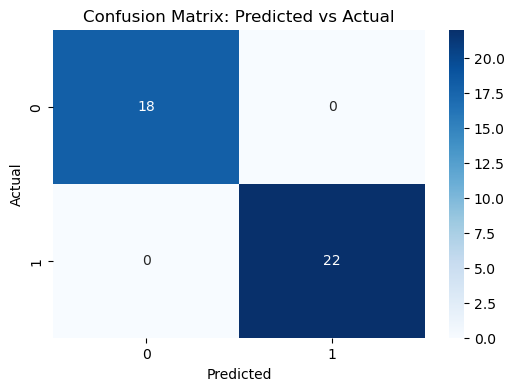

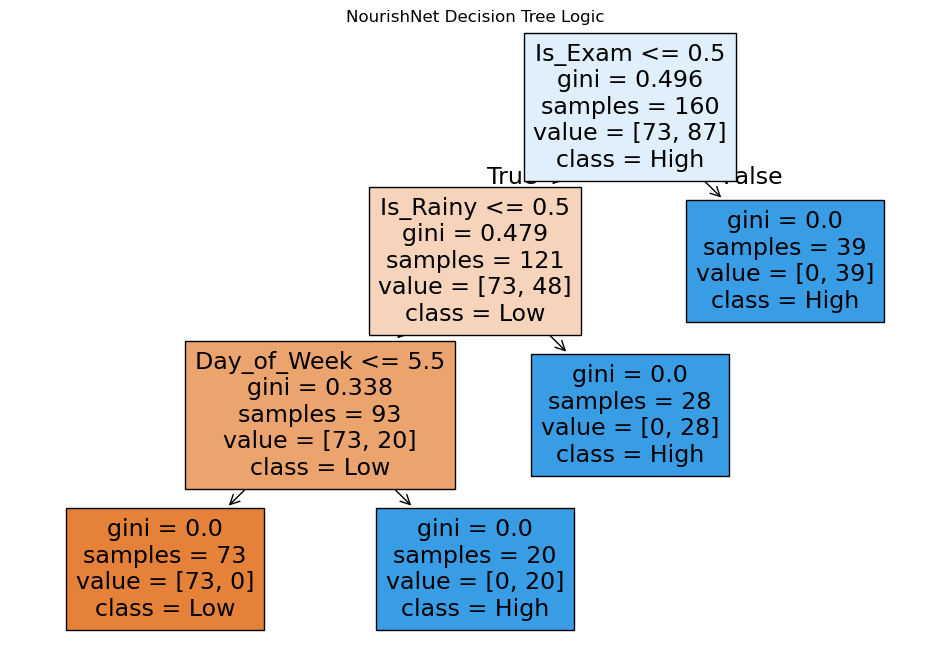

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- STEP 1: GENERATE SAMPLE DATASET ---
np.random.seed(42)
num_samples = 200

data = {
    'Day_of_Week': np.random.randint(0, 7, num_samples),      # 0=Mon, 6=Sun
    'Is_Exam': np.random.choice([0, 1], num_samples, p=[0.7, 0.3]),
    'Is_Rainy': np.random.choice([0, 1], num_samples, p=[0.8, 0.2]),
    'Previous_Day_Orders': np.random.randint(1, 7, num_samples)
}

df = pd.DataFrame(data)

# Target: 1 (High Demand/Cook 6 tiffins) if Day is Sunday or Exam or Rainy
# Otherwise 0 (Low Demand/Cook 2-3 tiffins)
df['Demand_Label'] = ((df['Day_of_Week'] == 6) | (df['Is_Exam'] == 1) | (df['Is_Rainy'] == 1)).astype(int)

# --- STEP 2: TRAIN-TEST SPLIT ---
X = df.drop('Demand_Label', axis=1)
y = df['Demand_Label']

# Splitting 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- STEP 3: MODEL TRAINING ---
model = DecisionTreeClassifier(max_depth=3)
model.fit(X_train, y_train)

# --- STEP 4: ACCURACY & CONFUSION MATRIX ---
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(conf_matrix)

# --- STEP 5: VISUALIZATION (FOR YOUR PPT) ---
# 1. Confusion Matrix Heatmap
plt.figure(figsize=(6,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix: Predicted vs Actual")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 2. The Decision Tree (The "Logic" slide)
plt.figure(figsize=(12,8))
plot_tree(model, feature_names=X.columns, class_names=['Low', 'High'], filled=True)
plt.title("NourishNet Decision Tree Logic")
plt.show()